<a href="https://colab.research.google.com/github/nattaponm/Teach_Tdating_strom_tracks_HID_CloudProperties/blob/main/notebooks/01_tdating_tracks_multiresolution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 1: ติดตามเส้นทางพายุด้วย T-DaTing ที่ความละเอียด 15, 10 และ 5 นาที
### Storm tracking with T-DaTing at three temporal resolutions — and what synthetic frames do to the tracks

⏱️ เวลาเรียนโดยประมาณ **75 นาที** | พื้นฐาน: repo *Teach_Pysteps_KKN_summerStorm* NB3 และ NB6

**เคสศึกษา:** พายุฤดูร้อน 3 พ.ค. 2567 เรดาร์ขอนแก่น (KKN) ช่วง 12:00–24:00 น. (05:00–17:00 UTC)

---
## 🎯 วัตถุประสงค์การเรียนรู้
เมื่อจบ notebook นี้ นิสิตจะสามารถ
1. **อธิบายขั้นตอนของ T-DaTing**: การตรวจจับเซลล์ด้วยหลายเกณฑ์ และการจับคู่เซลล์ระหว่างภาพ
2. **สร้างภาพความละเอียดสูงขึ้นด้วย advection interpolation** และประเมินคุณภาพของภาพสังเคราะห์อย่างเป็นปริมาณ
3. **ติดตามพายุที่ Δt = 15, 10, 5 นาที** และทำแผนที่เส้นทางคุณภาพตีพิมพ์บนภาพภูมิประเทศ
4. **เปรียบเทียบสถิติเส้นทาง** (จำนวน อายุ ความยาว) และอธิบายว่าความแตกต่างมาจากพายุหรือจากวิธีการ
5. **ระบุเส้นทางของพายุที่ก่อความเสียหาย** ที่ภูกระดึงและนากลาง

## 📖 1. แนวคิดและสมการ

### 1.1 T-DaTing (Thunderstorm Detection and Tracking; Hering et al., 2004; pysteps)
**ขั้นที่ 1 — ตรวจจับเซลล์ (detection)** ในแต่ละภาพ
- หาพื้นที่ที่ $Z \ge$ `minref` (33 dBZ) แล้วไล่เกณฑ์ขึ้นทีละ `mindiff` (5 dB) จนถึง `maxref` (45 dBZ) เพื่อแยกเซลล์ที่ติดกัน
- เก็บเฉพาะเซลล์ที่ใหญ่กว่า `minsize` (15 pixel = 15 km²) และมีค่าสูงสุด ≥ `minmax` (40 dBZ), ห่างกันอย่างน้อย `mindis` (8 km)

**ขั้นที่ 2 — จับคู่ (tracking)** ระหว่างภาพเวลา $t$ และ $t+\Delta t$
- คาดตำแหน่งเซลล์เดิมจากการเคลื่อนที่ที่ผ่านมา แล้ววัด **สัดส่วนพื้นที่ซ้อนทับ**
$$ f = \frac{|C_t^{\,adv} \cap C_{t+\Delta t}|}{|C_{t+\Delta t}|} \;\ge\; \texttt{match\_frac}\ (0.25) $$
- ถ้าจับคู่ได้ = เส้นทางเดิม, ถ้าไม่ได้ = เส้นทางใหม่; เส้นทางต้องมีอย่างน้อย `mintrack` (2) ภาพ

### 1.2 Advection interpolation: สร้างภาพระหว่าง 15 นาที
ใช้ motion field $\mathbf{V}$ (Lucas–Kanade) เลื่อนภาพก่อน $Z_A$ และหลัง $Z_B$ ไปยังเวลา $t + w\Delta t$ ($0<w<1$)
$$ Z_A' = Z_A(\mathbf{x} - w\mathbf{V}),\qquad Z_B' = Z_B(\mathbf{x} + (1-w)\mathbf{V}) $$
| วิธี | สูตร | ข้อดี | ข้อเสีย |
|---|---|---|---|
| **linZ** | $Z = 10\log_{10}\big[(1-w)\,10^{Z_A'/10} + w\,10^{Z_B'/10}\big]$ | เปลี่ยนแปลงเรียบ | แกนพายุที่ไม่ซ้อนกันพอดีถูกเฉลี่ยจน **อ่อนลง** |
| **nearest** | $Z = Z_A'$ ถ้า $w \le 0.5$ มิฉะนั้น $Z_B'$ | รักษาความเข้มของแกน | รูปร่าง "กระโดด" กลางช่วง |

> ⚠️ ภาพ 5/10 นาทีเป็น **ภาพสังเคราะห์** ไม่ใช่การวัด — ไม่สร้างเซลล์ใหม่ที่เกิดขึ้นระหว่างภาพจริง และไม่ทำให้ "รู้" มากกว่าข้อมูล 15 นาที

### 1.3 ทำไมความละเอียดเวลาจึงสำคัญ
พายุเคลื่อนที่ 20–50 km/h → ใน 15 นาทีเคลื่อนได้ 5–12 km ใกล้เคียงขนาดเซลล์ (5–15 km) จึงอาจ **ไม่ซ้อนทับ** กันระหว่างภาพ ทำให้เส้นทางขาด
ภาพที่ถี่ขึ้นช่วยให้ซ้อนทับกันง่ายขึ้น — แต่ถ้าเป็นภาพสังเคราะห์ ความต่อเนื่องนั้นอาจเป็น "ผลของวิธีการ"

## ⚙️ 2. เตรียมสภาพแวดล้อมและข้อมูล

In [1]:
#@title ⚙️ Setup: ติดตั้งแพ็กเกจและดาวน์โหลดข้อมูล (รันก่อนเสมอ ~2–4 นาทีใน Colab)
import os, sys, warnings
warnings.filterwarnings("ignore")

REPO = "Teach_Tdating_strom_tracks_HID_CloudProperties"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q pysteps==1.21.5 arm_pyart cartopy netCDF4 geopandas metpy cmweather rasterio scikit-image
    if not os.path.exists(REPO):
        !git clone -q --depth 1 https://github.com/nattaponm/{REPO}.git

for ROOT in [REPO, ".", ".."]:
    if os.path.exists(os.path.join(ROOT, "utils", "track_tools.py")):
        break
ROOT = os.path.abspath(ROOT)
sys.path.insert(0, ROOT)
DATA = os.path.join(ROOT, "data")
DER = os.path.join(DATA, "derived")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import track_tools as tt
from utils import mapplot as mp
from utils import kkn_tools as kt
mp.set_style()
mp.set_data_dir(DATA)
print("✅ พร้อมใช้งาน | ข้อมูลอยู่ที่:", DATA)

✅ พร้อมใช้งาน | ข้อมูลอยู่ที่: /content/Teach_Tdating_strom_tracks_HID_CloudProperties/data


In [2]:
Z15, meta = tt.load_cube(os.path.join(DER, "KKN_20240503_cappi_15min.nc"))
t15 = list(meta["timestamps"])
reports = kt.load_reports(DATA, meta)
terr = tt.load_terrain(os.path.join(DER, "KKN_20240503_terrain_1km.nc"))
NW = kt.box_around(meta, 102.3, 17.3, 90)
date0 = t15[0].replace(hour=0, minute=0)
print(f"CAPPI 15 นาที: {len(t15)} ภาพ ({t15[0]:%H:%M}–{t15[-1]:%H:%M} UTC) | พารามิเตอร์ T-DaTing: {tt.PARAMS}, {tt.TRACK_KW}")

CAPPI 15 นาที: 49 ภาพ (05:00–17:00 UTC) | พารามิเตอร์ T-DaTing: {'minref': 33, 'maxref': 45, 'mindiff': 5, 'minsize': 15, 'minmax': 40, 'mindis': 8}, {'mintrack': 2, 'match_frac': 0.25}


## 🔍 3. ตรวจจับเซลล์ในภาพเดียว: 09:30 UTC (16:30 น.)

Pysteps configuration file found at: /usr/local/lib/python3.13/dist-packages/pysteps/pystepsrc



บันทึกรูปแล้ว: figures/nb1_detection_0930.png, figures/nb1_detection_0930.pdf


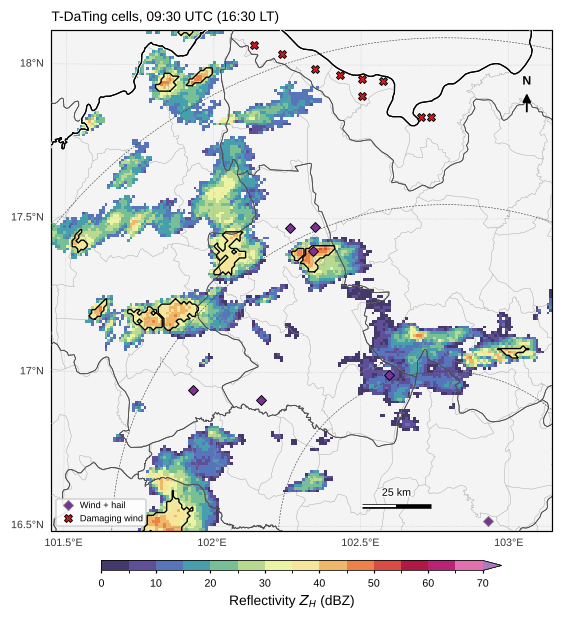

พบ 20 เซลล์ทั้งรัศมี | พื้นที่มัธยฐาน 49 km², Z สูงสุดมัธยฐาน 46.0 dBZ


In [3]:
from pysteps.feature import tstorm
import contextlib, io
i = t15.index(date0.replace(hour=9, minute=30))
with contextlib.redirect_stdout(io.StringIO()):
    cells, _ = tstorm.detection(np.nan_to_num(Z15[i], nan=-15.0), time=t15[i], **tt.PARAMS)
fig, axs = mp.map_panels(1, 1, meta, panel_width=5.0, zoom=NW)
im = mp.radar_map(axs[0], Z15[i], meta, zoom=NW, title=f"T-DaTing cells, {mp.tlabel(t15[i])}")
crs = mp.get_crs(meta)
for _, c in cells.iterrows():
    for x, y in kt.contour_xy(c["cont"], meta):
        axs[0].plot(x, y, color="k", lw=0.9, transform=crs, zorder=6)
mp.add_reports(axs[0], reports)
mp.add_colorbar(fig, im, axs, shrink=0.8)
mp.save_figure(fig, "nb1_detection_0930")
plt.show()
print(f"พบ {len(cells)} เซลล์ทั้งรัศมี | พื้นที่มัธยฐาน {cells['area'].median():.0f} km², Z สูงสุดมัธยฐาน {cells['max_ref'].median():.1f} dBZ")

## 🧭 4. ติดตามพายุที่ Δt = 15 นาที (รันเอง ~40 วินาที)

In [4]:
import time
t0 = time.time()
tracks15 = tt.run_tdating(Z15, t15)
lab15 = tt.tracks_to_labels(tracks15, t15, Z15.shape[1:])
C15 = tt.add_motion(tt.cell_table(lab15, Z15, t15, meta, terrain=terr), terr, meta)
T15 = tt.track_table(C15)
print(f"T-DaTing ใช้เวลา {time.time() - t0:.0f} s | {len(T15)} เส้นทาง, {len(C15)} เซลล์")
T15.sort_values("Zmax_all", ascending=False).head(8)[["start", "lifetime_min", "path_km", "speed_kmh", "dir_to_deg",
                                                       "Zmax_all", "area_max", "dem_start"]].round(1)

T-DaTing ใช้เวลา 43 s | 114 เส้นทาง, 339 เซลล์


,start,lifetime_min,path_km,speed_kmh,dir_to_deg,Zmax_all,area_max,dem_start
track_id,,,,,,,,
52,2024-05-03 09:15:00,45.0,12.9,9.2,114.6,55.5,144.0,177.6
51,2024-05-03 09:15:00,60.0,18.1,13.0,113.2,54.5,175.0,485.9
48,2024-05-03 09:00:00,90.0,39.2,19.0,100.1,54.0,174.0,190.9
90,2024-05-03 12:45:00,60.0,40.0,29.4,46.3,54.0,144.0,191.5
12,2024-05-03 07:00:00,30.0,17.9,17.7,134.6,53.9,157.0,253.0
4,2024-05-03 06:00:00,90.0,13.2,2.0,351.8,53.5,76.0,221.5
13,2024-05-03 07:00:00,45.0,29.6,16.4,113.5,53.4,246.0,175.3
25,2024-05-03 07:45:00,15.0,6.7,0.0,0.0,52.9,62.0,206.7


## 🧪 5. ภาพสังเคราะห์เชื่อได้แค่ไหน? (ผลทดสอบ leave-one-out จาก 00)
ใช้ภาพทุก 30 นาทีแทรกกลับเป็น 15 นาที แล้วเทียบกับภาพจริงที่ตัดออก — เป็นการทดสอบที่ "ยากกว่า" การแทรก 5 นาที แต่บอกแนวโน้มได้

             CSI35  CSI45  RMSE_dB  A45_ratio
method                                       
linZ         0.184    0.0   21.353      0.131
nearest      0.160    0.0   24.682      0.463
persistence  0.073    0.0   29.228      0.931


บันทึกรูปแล้ว: figures/nb1_interpolation_example.png, figures/nb1_interpolation_example.pdf


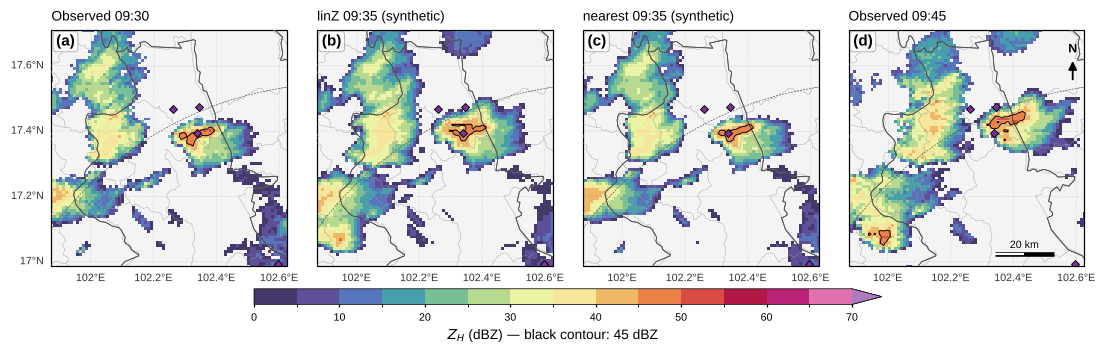

In [5]:
loo = pd.read_csv(os.path.join(DER, "KKN_20240503_interp_test.csv"), parse_dates=["time"])
sk = loo.groupby("method")[["CSI35", "CSI45", "RMSE_dB", "A45_ratio"]].median().round(3)
print(sk)
Z5n, _ = tt.load_cube(os.path.join(DER, "KKN_20240503_cappi_05min_nearest.nc"))
Z5l, m5 = tt.load_cube(os.path.join(DER, "KKN_20240503_cappi_05min_linZ.nc"))
t5 = list(m5["timestamps"])
ZNK = kt.box_around(meta, 102.25, 17.35, 40)
j = t5.index(date0.replace(hour=9, minute=35))
panels = [(Z5n[j - 1], "Observed 09:30"), (Z5l[j], "linZ 09:35 (synthetic)"),
          (Z5n[j], "nearest 09:35 (synthetic)"), (Z5n[j + 2], "Observed 09:45")]
fig, axs = mp.map_panels(1, 4, meta, panel_width=2.5, zoom=ZNK)
for k, (ax, (img, ttl)) in enumerate(zip(axs, panels)):
    im = mp.radar_map(ax, img, meta, zoom=ZNK, title=ttl, gridline_labels=("left", "bottom") if k == 0 else ("bottom",),
                      north=(k == 3), scalebar=(k == 3))
    mp.obs_contour(ax, img, meta, level=45, color="k", linewidth=0.6)
    mp.add_reports(ax, reports, legend=False, ms=4)
mp.panel_labels(axs)
mp.add_colorbar(fig, im, axs, shrink=0.6, label="$Z_H$ (dBZ) — black contour: 45 dBZ")
mp.save_figure(fig, "nb1_interpolation_example")
plt.show()

- ภาพสังเคราะห์ทั้งสองวิธีดีกว่าการใช้ภาพเดิมซ้ำ (persistence) ที่ 35 dBZ แต่ **CSI ที่ 45 dBZ ≈ 0** — แกนพายุเปลี่ยนเร็วกว่าที่การเลื่อนภาพจะจับได้
- **linZ** ทำให้พื้นที่ ≥ 45 dBZ หายไปมาก (`A45_ratio` ต่ำ) ขณะที่ **nearest** รักษาความเข้มไว้ได้ดีกว่า
- แต่ nearest มีรูปร่าง "กระโดด" กลางช่วง (ภาพที่ 5 นาทีเลื่อนจากภาพก่อน ภาพที่ 10 นาทีเลื่อนจากภาพหลัง) — section 6 จะเห็นว่าทำให้ **เส้นทางขาดบ่อย**
- ข้อสรุป: ภาพสังเคราะห์ใช้ "เชื่อมเส้นทาง" ได้ แต่ **ไม่ควรใช้วัดความเข้ม** — ค่า Z, HID, Doppler ใน NB3–NB5 จึงใช้เฉพาะเวลาที่วัดจริง

## 🗺️ 6. เส้นทางพายุที่ 15, 10 และ 5 นาที

In [6]:
SETS = {}
for tag in tt.TAGS:
    S = tt.load_set(DER, tag)
    C = tt.add_motion(tt.cell_table(S["labels"], S["Z"], S["times"], meta, terrain=terr), terr, meta)
    SETS[tag] = {"C": C, "T": tt.track_table(C), **S}
rows = []
for tag, S in SETS.items():
    T = S["T"]
    rows.append({"set": tag, "frames": len(S["times"]), "tracks": len(T), "life≥30 min": int((T.lifetime_min >= 30).sum()),
                 "life≥60 min": int((T.lifetime_min >= 60).sum()), "median life (min)": T.lifetime_min.median(),
                 "max life (min)": T.lifetime_min.max(), "median path (km)": T.path_km.median()})
summary = pd.DataFrame(rows).set_index("set").round(1)
summary

,frames,tracks,life≥30 min,life≥60 min,median life (min),max life (min),median path (km)
set,,,,,,,
15min,49,114,59,12,30.0,120.0,11.0
10min_linZ,73,160,62,18,20.0,140.0,9.6
05min_linZ,145,208,68,24,20.0,135.0,9.8
10min_nearest,73,184,48,11,20.0,120.0,7.6
05min_nearest,145,304,46,8,10.0,130.0,6.2


บันทึกรูปแล้ว: figures/nb1_tracks_three_resolutions.png, figures/nb1_tracks_three_resolutions.pdf


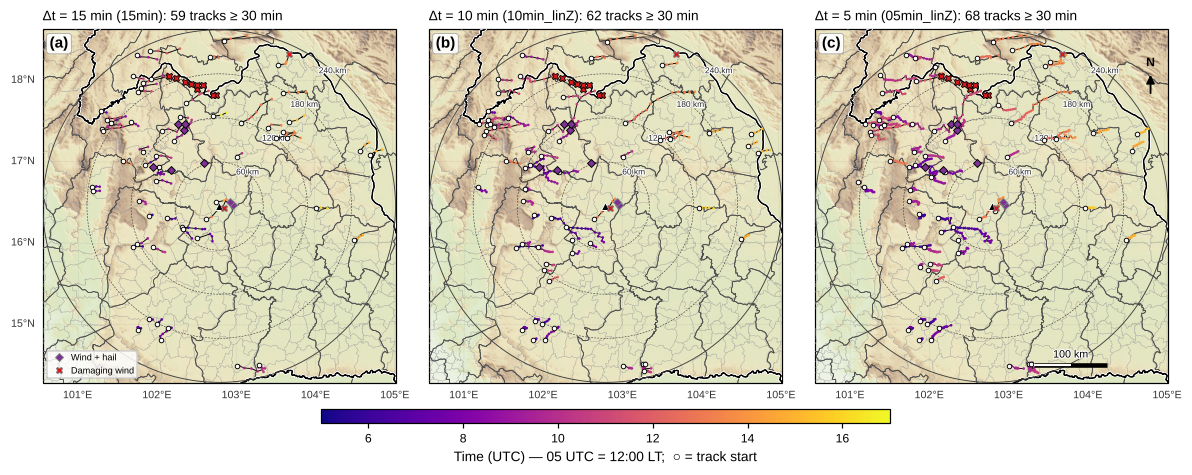

In [7]:
fig, axs = mp.map_panels(1, 3, meta, panel_width=3.6)
for k, (ax, dt) in enumerate(zip(axs, (15, 10, 5))):
    S = SETS[tt.MAIN[dt]]
    ax.set_extent(mp.extent_of(meta), crs=mp.get_crs(meta))
    mp.add_terrain(ax, meta)
    mp.add_basemap(ax, meta, labels=("left", "bottom") if k == 0 else ("bottom",))
    sc = tt.plot_tracks(ax, S["C"], meta, min_life=30)
    mp.add_reports(ax, reports, legend=(k == 0), ms=4)
    n30 = int((S["T"].lifetime_min >= 30).sum())
    ax.set_title(f"Δt = {dt} min ({S['tag']}): {n30} tracks ≥ 30 min", loc="left", fontsize=9)
    if k == 2:
        mp.add_scalebar(ax); mp.add_north_arrow(ax)
mp.panel_labels(axs)
cb = fig.colorbar(sc, ax=list(axs), orientation="horizontal", shrink=0.5, pad=0.02, aspect=40)
cb.set_label("Time (UTC) — 05 UTC = 12:00 LT;  ○ = track start")
mp.save_figure(fig, "nb1_tracks_three_resolutions")
plt.show()

**อ่านแผนที่:**
- เส้นทางส่วนใหญ่เริ่มบน **พื้นที่สูงทางตะวันตก (เลย–เพชรบูรณ์)** ช่วงเที่ยง–บ่าย แล้วเคลื่อนไปทาง **ตะวันออก–ตะวันออกเฉียงเหนือ**
- ที่ Δt = 5 นาที (linZ) เส้นทางต่อเนื่องและยาวขึ้น ช่องว่างระหว่างจุดหายไป — แต่ต้องจำว่า 2 ใน 3 ของภาพเป็นภาพสังเคราะห์
- ตารางด้านบน: ชุด **nearest มีเส้นทางมากแต่สั้น** (อายุ ≥ 30 นาทีน้อยกว่า 15 นาทีด้วยซ้ำ) เพราะรูปร่างกระโดดทำให้ซ้อนทับไม่ถึง `match_frac`
  ขณะที่ **linZ** ต่อเนื่องกว่า → repo นี้ใช้ **linZ เป็นชุดหลักสำหรับการติดตาม** และดึงความเข้มจากภาพจริงเท่านั้น (ข้อแลกเปลี่ยนที่ต้องเลือกตามวัตถุประสงค์)
- พายุช่วงค่ำ (สีส้ม–เหลือง) อยู่ทางตอนเหนือ (หนองคาย–บึงกาฬ) และใกล้ขอนแก่น

## 📊 7. อายุของเส้นทาง: เกณฑ์จำนวนภาพ vs เกณฑ์อายุจริง

บันทึกรูปแล้ว: figures/nb1_lifetime_distribution.png, figures/nb1_lifetime_distribution.pdf


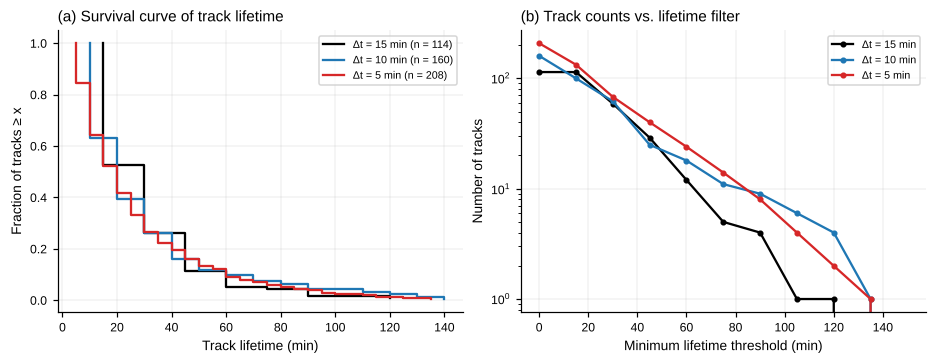

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(8.4, 3.2), layout="constrained")
cols = {15: "k", 10: "tab:blue", 5: "tab:red"}
for dt in (15, 10, 5):
    T = SETS[tt.MAIN[dt]]["T"]
    x = np.sort(T.lifetime_min.values)
    axs[0].step(x, 1 - np.arange(len(x)) / len(x), where="post", color=cols[dt], label=f"Δt = {dt} min (n = {len(x)})")
    thr = np.arange(0, 151, 15)
    axs[1].plot(thr, [(T.lifetime_min >= t).sum() for t in thr], "o-", color=cols[dt], ms=3, label=f"Δt = {dt} min")
axs[0].set_xlabel("Track lifetime (min)"); axs[0].set_ylabel("Fraction of tracks ≥ x"); axs[0].legend(fontsize=7)
axs[0].set_title("(a) Survival curve of track lifetime", loc="left")
axs[1].set_xlabel("Minimum lifetime threshold (min)"); axs[1].set_ylabel("Number of tracks"); axs[1].legend(fontsize=7)
axs[1].set_yscale("log"); axs[1].set_title("(b) Track counts vs. lifetime filter", loc="left")
for ax in axs:
    ax.grid(lw=0.3, alpha=0.5)
mp.save_figure(fig, "nb1_lifetime_distribution")
plt.show()

- จำนวนเส้นทาง "ทั้งหมด" ต่างกันมาก เพราะ Δt เล็กทำให้เส้นทางสั้น ๆ (2–3 ภาพ = 10–15 นาที) ผ่านเกณฑ์ `mintrack` ได้ง่าย
- เมื่อใช้ **เกณฑ์อายุจริง** (เช่น ≥ 30 นาที) จำนวนเส้นทางของทั้งสามความละเอียด **ใกล้กันมากขึ้น** → ในงานวิจัย ควรกรองด้วยเวลาจริง ไม่ใช่จำนวนภาพ
- จาก NB2 เป็นต้นไป วิเคราะห์เฉพาะ **เส้นทางที่อายุ ≥ 30 นาที**

## 🎯 8. เส้นทางของพายุที่ก่อความเสียหาย

In [9]:
rows = []
for name in ("Phu Kradueng", "Na Klang"):
    s = kt.site(reports, name)
    tr = kt.report_time_utc(s, date0)
    for dt in (15, 10, 5):
        S = SETS[tt.MAIN[dt]]
        near = tt.tracks_near(S["T"], S["C"], s["lon"], s["lat"], t_ref=tr, radius_km=15, window_min=45, meta=meta)
        if near.empty:
            rows.append({"site": name, "dt": dt}); continue
        b = near.iloc[0]
        rows.append({"site": name, "dt": dt, "track_id": int(near.index[0]), "min_dist_km": b.min_dist_km,
                     "start": b.start.strftime("%H:%M"), "end": b.end.strftime("%H:%M"), "lifetime_min": b.lifetime_min,
                     "path_km": b.path_km, "speed_kmh": b.speed_kmh, "Zmax_obs": b.Zmax_obs})
key_tracks = pd.DataFrame(rows).set_index(["site", "dt"]).round(1)
key_tracks

track_id  min_dist_km  start    end  lifetime_min  path_km  \
site         dt                                                               
Phu Kradueng 15         8          5.1  06:45  07:00          15.0     11.8   
             10         9          5.1  06:40  09:00         140.0     71.8   
             5         10          2.1  06:35  08:05          90.0     64.2   
Na Klang     15        38          1.3  08:45  10:15          90.0     38.4   
             10        40          1.3  08:40  10:10          90.0     39.9   
             5         54          1.3  08:40  10:15          95.0     44.2   

                 speed_kmh  Zmax_obs  
site         dt                       
Phu Kradueng 15        0.0      50.9  
             10       19.0      48.4  
             5        25.5      50.9  
Na Klang     15       20.1      51.7  
             10       24.9      51.4  
             5        25.8      51.7

---
## 🧪 แบบฝึกหัด

### 🧪 แบบฝึกหัด 1.1: เกณฑ์ `minref` มีผลต่อเส้นทางแค่ไหน?
รัน T-DaTing ที่ Δt = 15 นาที เฉพาะช่วง **07:00–11:00 UTC** ด้วย `minref` = 30, 33, 36 dBZ (พารามิเตอร์อื่นคงเดิม)
แล้วเปรียบเทียบจำนวนเส้นทาง, จำนวนที่อายุ ≥ 30 นาที และอายุมัธยฐาน

**คำถาม:** ถ้าเลือก minref ต่ำเกินไป/สูงเกินไป จะเกิดอะไรกับการตีความ "อายุของพายุ"?

<details>
<summary><b>💡 คำใบ้</b></summary>

- ตัดช่วงเวลา: `a, b = t15.index(date0.replace(hour=7)), t15.index(date0.replace(hour=11))`
- `tr = tt.run_tdating(Z15[a:b + 1], t15[a:b + 1], params={"minref": m})`
- อายุ: `(tr_k["time"].iloc[-1] - tr_k["time"].iloc[0]).total_seconds() / 60`

</details>

In [10]:
# ✍️ แบบฝึกหัด 1.1 — เขียนโค้ดของคุณที่นี่

In [11]:
#@title ✅ เฉลยแบบฝึกหัด 1.1
a, b = t15.index(date0.replace(hour=7)), t15.index(date0.replace(hour=11))
res = []
for m in (30, 33, 36):
    tr = tt.run_tdating(Z15[a:b + 1], t15[a:b + 1], params={"minref": m})
    life = np.array([(pd.Timestamp(x["time"].iloc[-1]) - pd.Timestamp(x["time"].iloc[0])).total_seconds() / 60 for x in tr])
    area = np.array([x["area"].mean() for x in tr])
    res.append({"minref": m, "tracks": len(tr), "life≥30": int((life >= 30).sum()), "median_life": np.median(life),
                "median_cell_area_km2": np.median(area)})
res = pd.DataFrame(res).set_index("minref").round(1)
print(res)
print("\n→ minref ต่ำ: เซลล์ใหญ่และรวมกันง่าย เส้นทางยาวขึ้น (พายุดู 'อายุยืน') แต่หลายเซลล์ถูกรวมเป็นก้อนเดียว"
      "\n  minref สูง: เห็นเฉพาะแกน เซลล์เล็กลง ซ้อนทับกันยาก เส้นทางขาดง่าย → อายุสั้นลง"
      "\n  'อายุของพายุ' จึงขึ้นกับนิยามเกณฑ์ — ต้องรายงานพารามิเตอร์และทดสอบความไวเสมอ")

        tracks  life≥30  median_life  median_cell_area_km2
minref                                                    
30          56       31         30.0                  78.8
33          54       25         15.0                  64.2
36          44       17         15.0                  56.8

→ minref ต่ำ: เซลล์ใหญ่และรวมกันง่าย เส้นทางยาวขึ้น (พายุดู 'อายุยืน') แต่หลายเซลล์ถูกรวมเป็นก้อนเดียว
  minref สูง: เห็นเฉพาะแกน เซลล์เล็กลง ซ้อนทับกันยาก เส้นทางขาดง่าย → อายุสั้นลง
  'อายุของพายุ' จึงขึ้นกับนิยามเกณฑ์ — ต้องรายงานพารามิเตอร์และทดสอบความไวเสมอ


### 🧪 แบบฝึกหัด 1.2: linZ กับ nearest ให้เส้นทางและความเข้มต่างกันอย่างไร?
ใช้ `SETS["05min_linZ"]` และ `SETS["05min_nearest"]` เปรียบเทียบ
(1) จำนวนเส้นทางอายุ ≥ 30 นาที และอายุมัธยฐาน (2) Zmax และพื้นที่ ≥ 45 dBZ ของเซลล์ แยกตาม **ภาพจริง vs ภาพสังเคราะห์** (คอลัมน์ `observed`)

**คำถาม:** ถ้าใช้ภาพสังเคราะห์คำนวณ "ความแรงสูงสุดของเส้นทาง" จะเกิด bias อย่างไร?

<details>
<summary><b>💡 คำใบ้</b></summary>

- `C.groupby("observed")[["Zmax", "A45_km2"]].median()`
- ใช้ boxplot: `tt.boxplot_groups(ax, C.assign(kind=...), "Zmax", "kind")`

</details>

In [12]:
# ✍️ แบบฝึกหัด 1.2 — เขียนโค้ดของคุณที่นี่

               tracks≥30  median_life  Zmax_obs  A45_obs  Zmax_synth  \
set                                                                    
05min_linZ            68         20.0      46.0     4.76        43.7   
05min_nearest         46         10.0      46.0     4.40        44.5   

               A45_synth  
set                       
05min_linZ          1.77  
05min_nearest       2.93  


บันทึกรูปแล้ว: figures/nb1_ex12_synthetic_bias.png, figures/nb1_ex12_synthetic_bias.pdf


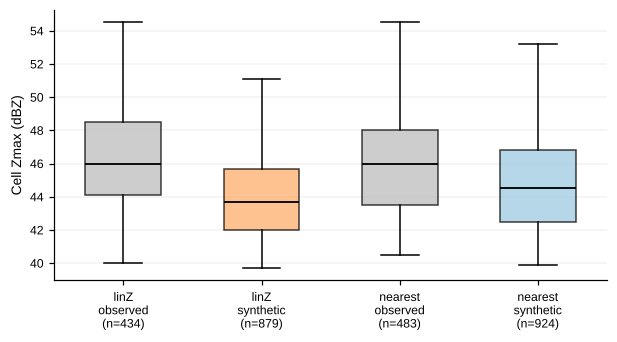

→ เซลล์ในภาพ linZ อ่อนกว่าภาพจริงอย่างเป็นระบบ (Z สูงสุดต่ำลงและพื้นที่ ≥45 dBZ น้อยลง) ส่วน nearest ใกล้ภาพจริงกว่า
  ถ้าคำนวณความแรงของเส้นทางจากทุกภาพ จะได้ค่าต่ำกว่าจริง → ใช้เฉพาะภาพจริง (Zmax_obs) ในการเปรียบเทียบ


In [13]:
#@title ✅ เฉลยแบบฝึกหัด 1.2
rows, frames = [], []
for tag in ("05min_linZ", "05min_nearest"):
    C, T = SETS[tag]["C"], SETS[tag]["T"]
    r = {"set": tag, "tracks≥30": int((T.lifetime_min >= 30).sum()), "median_life": T.lifetime_min.median()}
    for obs, lab in ((True, "obs"), (False, "synth")):
        r[f"Zmax_{lab}"] = C.loc[C.observed == obs, "Zmax"].median()
        r[f"A45_{lab}"] = C.loc[C.observed == obs, "A45_km2"].mean()
    rows.append(r)
    frames.append(C.assign(kind=np.where(C.observed, f"{tag.split('_')[1]}\nobserved", f"{tag.split('_')[1]}\nsynthetic")))
print(pd.DataFrame(rows).set_index("set").round(2))
D = pd.concat(frames)
D["kind"] = pd.Categorical(D["kind"], ["linZ\nobserved", "linZ\nsynthetic", "nearest\nobserved", "nearest\nsynthetic"])
fig, ax = plt.subplots(figsize=(5.5, 3), layout="constrained")
tt.boxplot_groups(ax, D, "Zmax", "kind", ylabel="Cell Zmax (dBZ)", points=False,
                  colors=["#bdbdbd", "#fdae6b", "#bdbdbd", "#9ecae1"])
mp.save_figure(fig, "nb1_ex12_synthetic_bias")
plt.show()
print("→ เซลล์ในภาพ linZ อ่อนกว่าภาพจริงอย่างเป็นระบบ (Z สูงสุดต่ำลงและพื้นที่ ≥45 dBZ น้อยลง) ส่วน nearest ใกล้ภาพจริงกว่า"
      "\n  ถ้าคำนวณความแรงของเส้นทางจากทุกภาพ จะได้ค่าต่ำกว่าจริง → ใช้เฉพาะภาพจริง (Zmax_obs) ในการเปรียบเทียบ")

### 🧪 แบบฝึกหัด 1.3: พายุนากลางในสามความละเอียด
จากตาราง `key_tracks` ดึงเส้นทางของ **นากลาง** ที่ Δt = 15, 10, 5 นาที แล้วพลอตเส้นทาง centroid ทั้งสามซ้อนกันบนแผนที่ซูม
เปรียบเทียบเวลาเริ่ม–จบ อายุ และความเร็ว

**คำถาม:** ทำไมเวลาเริ่มของเส้นทางจึงอาจต่างกันได้ ทั้งที่เป็นพายุลูกเดียวกัน? เส้นทางใดน่าเชื่อถือที่สุดสำหรับรายงานภัยพิบัติ?

<details>
<summary><b>💡 คำใบ้</b></summary>

- `tid = key_tracks.loc[("Na Klang", dt), "track_id"]`
- `g = SETS[tt.MAIN[dt]]["C"].query("track_id == @tid")` แล้ว `ax.plot(g.cx, g.cy, transform=mp.get_crs(meta))`

</details>

In [14]:
# ✍️ แบบฝึกหัด 1.3 — เขียนโค้ดของคุณที่นี่

บันทึกรูปแล้ว: figures/nb1_ex13_naklang_tracks.png, figures/nb1_ex13_naklang_tracks.pdf


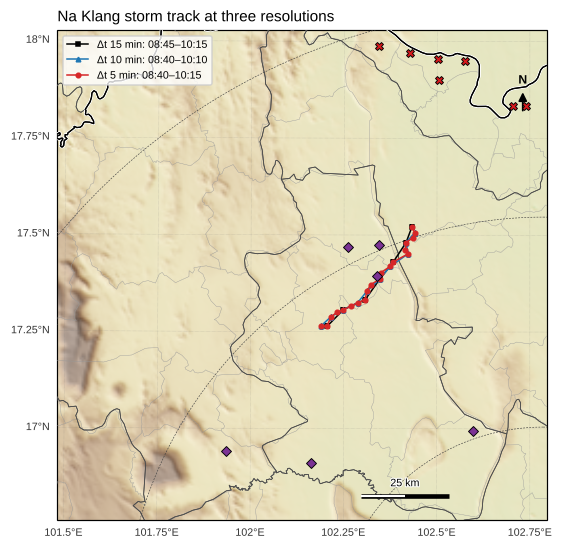

    track_id  min_dist_km  start    end  lifetime_min  path_km  speed_kmh  \
dt                                                                          
15        38          1.3  08:45  10:15          90.0     38.4       20.1   
10        40          1.3  08:40  10:10          90.0     39.9       24.9   
5         54          1.3  08:40  10:15          95.0     44.2       25.8   

    Zmax_obs  
dt            
15      51.7  
10      51.4  
5       51.7  

→ เวลาเริ่ม/จบต่างกันเพราะ (1) เส้นทางขาดหรือเชื่อมต่างกันเมื่อมีภาพแทรก (2) เซลล์อาจถูกนับเป็นเส้นทางใหม่หลัง split/merge
  สำหรับรายงานภัยพิบัติ ควรใช้ภาพจริง 15 นาทีเป็นหลัก และใช้ 5 นาทีช่วย 'เชื่อม' เมื่อเส้นทางขาด พร้อมระบุว่าเป็นค่าประมาณ


In [15]:
#@title ✅ เฉลยแบบฝึกหัด 1.3
s = kt.site(reports, "Na Klang")
ZB = kt.box_around(meta, s["lon"] - 0.2, s["lat"], 70)
fig, axs = mp.map_panels(1, 1, meta, panel_width=5, zoom=ZB)
ax = axs[0]
ax.set_extent(ZB, crs=mp.get_crs(meta)); mp.add_terrain(ax, meta); mp.add_basemap(ax, meta)
for dt, col, mk in ((15, "k", "s"), (10, "tab:blue", "^"), (5, "tab:red", "o")):
    if pd.isna(key_tracks.loc[("Na Klang", dt)].get("track_id", np.nan)):
        continue
    tid = int(key_tracks.loc[("Na Klang", dt), "track_id"])
    g = SETS[tt.MAIN[dt]]["C"].query("track_id == @tid")
    ax.plot(g.cx, g.cy, "-", marker=mk, ms=3, color=col, lw=1, transform=mp.get_crs(meta),
            label=f"Δt {dt} min: {g.time.iloc[0]:%H:%M}–{g.time.iloc[-1]:%H:%M}", zorder=8)
mp.add_reports(ax, reports, legend=False)
ax.legend(fontsize=7, loc="upper left"); mp.add_scalebar(ax); mp.add_north_arrow(ax)
ax.set_title("Na Klang storm track at three resolutions", loc="left")
mp.save_figure(fig, "nb1_ex13_naklang_tracks")
plt.show()
print(key_tracks.loc["Na Klang"])
print("\n→ เวลาเริ่ม/จบต่างกันเพราะ (1) เส้นทางขาดหรือเชื่อมต่างกันเมื่อมีภาพแทรก (2) เซลล์อาจถูกนับเป็นเส้นทางใหม่หลัง split/merge"
      "\n  สำหรับรายงานภัยพิบัติ ควรใช้ภาพจริง 15 นาทีเป็นหลัก และใช้ 5 นาทีช่วย 'เชื่อม' เมื่อเส้นทางขาด พร้อมระบุว่าเป็นค่าประมาณ")

---
## 📝 สรุป
- T-DaTing ตรวจจับเซลล์ด้วยเกณฑ์หลายระดับ และจับคู่ด้วยพื้นที่ซ้อนทับ — ผลขึ้นกับพารามิเตอร์ (minref) อย่างมาก
- ไม่มีข้อมูลถี่กว่า 15 นาที จึงสร้างภาพ 5/10 นาทีด้วย advection interpolation: **ดีกว่า persistence แต่แกน ≥45 dBZ ทำนายไม่ได้** และ linZ ทำให้แกนอ่อนลง
- ที่ Δt เล็ก เส้นทางต่อเนื่องขึ้นและนับได้มากขึ้น แต่เมื่อกรองด้วย **อายุจริง ≥ 30 นาที** ผลของทั้งสามความละเอียดใกล้กันขึ้น
- ภาพสังเคราะห์ใช้เชื่อมเส้นทาง — ค่าความเข้ม HID และ Doppler ต้องใช้จากภาพจริงเท่านั้น

### ❓ คำถามชวนคิด
1. ถ้า TMD สแกนทุก 5 นาทีจริง ผลของ notebook นี้จะเปลี่ยนไปอย่างไร? จะใช้ข้อมูลชุดนี้ "ประเมิน" ความคลาดเคลื่อนของภาพสังเคราะห์ได้อย่างไร
2. `match_frac` = 0.25 เหมาะกับทุก Δt หรือไม่? ถ้าพายุเคลื่อนเร็ว 50 km/h ควรปรับอย่างไร
3. เส้นทางที่เริ่มบนภูเขาทางตะวันตก บอกอะไรเกี่ยวกับกลไกการก่อตัวของพายุฤดูร้อนในอีสาน (จะทดสอบใน NB5)

**🚀 ต่อยอด (ป.โท):** ทำ **ensemble tracking** โดยรัน T-DaTing ด้วยชุดพารามิเตอร์หลายชุด (minref, match_frac, วิธีแทรกภาพ) แล้วรายงาน "ความน่าจะเป็นที่ pixel หนึ่งอยู่บนเส้นทางพายุ" แทนเส้นทางเดียว

### 📚 เอกสารอ้างอิง
- Hering, A. M., Morel, C., Galli, G., Sénési, S., Ambrosetti, P., & Boscacci, M. (2004). Nowcasting thunderstorms in the Alpine region using a radar based adaptive thresholding scheme. *Proc. ERAD*, 206–211.
- Pulkkinen, S., et al. (2019). Pysteps: an open-source Python library for probabilistic precipitation nowcasting (v1.0). *Geosci. Model Dev.*, 12, 4185–4219.
- Dixon, M., & Wiener, G. (1993). TITAN: Thunderstorm Identification, Tracking, Analysis, and Nowcasting — A radar-based methodology. *J. Atmos. Oceanic Technol.*, 10, 785–797.
- Lakshmanan, V., & Smith, T. (2010). An objective method of evaluating and devising storm-tracking algorithms. *Wea. Forecasting*, 25, 701–709.
- Germann, U., & Zawadzki, I. (2002). Scale-dependence of the predictability of precipitation from continental radar images. Part I. *Mon. Wea. Rev.*, 130, 2859–2873.